# T04 — Synthetic order flow

*How do I build my own order flow, without real data?*

**What you will learn**

- what a *tape* is: the 13 columns of an order row, and the padding rows;
- how to write a tape by hand with `TapeBuilder`;
- how to draw random, reproducible order flow with `FuzzRegime` and `make_random_session`;
- how to stack tapes of different lengths with `stack_tapes` and replay them through the matching engine.

**What you need**

- Previous tutorials: none. [T01](T01_first_contract.ipynb) explains the order book, and
  [T03](T03_real_data.ipynb) builds the same kind of tape from real OMIE data (both linked, not required).
- Run time: about 2 minutes on a central processing unit (CPU), mostly compiling the engine.
- Network: no.

## Setup

Imports, the device (CPU by default), the seeds, the figure style and the repository root.

In [1]:
# Setup: device, repository root, seeds and the figure style. Run this cell first.
import os
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # CPU by default; export JAX_PLATFORMS=cuda before Jupyter for a GPU

# The repository root is the first folder above this notebook that holds pyproject.toml.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
DATA_DIR = ROOT / "data" / "rawOMIE"  # every data path starts here (ignored by git), never under tutorials/

import jax
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 0  # fixed seeds: a re-run gives the same market results
rng = np.random.default_rng(SEED)
key = jax.random.PRNGKey(SEED)

# Figure style, the same five lines in every tutorial: buy, sell, a third series, neutral.
BUY, SELL, THIRD, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 110, "savefig.dpi": 110, "font.size": 9.5,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "legend.frameon": False, "axes.titlesize": 10.5,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
print(f"JAX {jax.__version__}, backend: {jax.default_backend()}")

JAX 0.6.2, backend: cpu


In [2]:
import dataclasses
import time

import jax.numpy as jnp

from omiecid_simulator.jaxomiecid.omie_data_loader import replay_orders_through_book
from omiecid_simulator.jaxomiecid.omie_tape_synth import FuzzRegime, TapeBuilder, make_random_session, stack_tapes
from omiecid_simulator.omiecid.contract import ContractStatus, generate_contracts
from omiecid_simulator.omiecid.contract_book import ContractBook
from omiecid_simulator.omiecid.encoding import decode_price, decode_qty
from omiecid_simulator.omiecid.omie_config import OMIEProductConfig
from omiecid_simulator.omiecid.omie_session import Session
from omiecid_simulator.omiecid.order_types import ExecRestriction, Side

PC = OMIEProductConfig()  # ticks and bounds: 0.01 EUR/MWh, 0.1 MW

## 1. What a tape is

> **Concept — a tape.** A *tape* is the time-ordered list of orders that drives a replay: the orders
> that other traders send to one contract. Each order is one row of 13 whole numbers. Prices and
> quantities are stored as whole numbers of *ticks* (0.01 euros per megawatt-hour, EUR/MWh, and 0.1
> megawatt, MW), so that they are exact.

| Column | Field | Meaning |
|---|---|---|
| 0 | contract | Quarter-hour slot of the delivery day, 0–95 |
| 1 | side | 0 buy, 1 sell |
| 2 | price | Price ticks above $-9{,}999$ EUR/MWh: $(p + 9{,}999) / 0.01$ |
| 3 | quantity | Quantity in ticks of 0.1 MW |
| 4 | order id | Positive; padding rows carry $\le 0$ |
| 5 | trader id | Anonymous participant number (in a loaded OMIE tape, one per bidding unit) |
| 6 | time | Seconds; padding rows carry $\le 0$ |
| 7 | order type | 0 limit (NON), 1 immediate-or-cancel (IOC), 2 fill-or-kill (FOK), 3 iceberg (ICE) |
| 8 | validity | 0 good-for-session (GFS: until gate closure), 1 good-till-date (GTD) |
| 9 | expiry time | 0 means gate closure |
| 10 | status | Order status code |
| 11 | peak | Iceberg visible peak, in quantity ticks |
| 12 | price increment | Price step of each new iceberg peak (iceberg with price increment, ICEwPI), in signed price ticks |

> **Concept — padding rows.** A tape ends with a few *padding rows*: rows whose order id and time are
> $\le 0$. The engine skips them. They let tapes of different lengths share one array shape, which
> compiled code needs: several tapes of different lengths become one block of equal-length tapes.

Synthetic tapes are useful for controlled experiments (you choose every order), for tests whose outcome
you know in advance, and for work without real data or its licence. [Data](../docs/data.md#the-tape-layout)
describes the same layout.

## 2. A tape by hand

`TapeBuilder` writes rows in readable units: prices in EUR/MWh, quantities in MW. It numbers the
orders 1, 2, 3, … and gives them times 30 seconds apart. The tape below builds a small two-sided book
around 50 EUR/MWh, adds an iceberg sell that shows 2 MW of its 6 MW at a time, and ends with an
immediate-or-cancel buy that crosses the asks: whatever it cannot fill at once is cancelled.

In [3]:
tb = TapeBuilder(timestamp_step=30)  # one order every 30 s, from second 1
for i in range(3):
    tb.add(side=Side.BUY, price_eur=49.0 - i, qty_mw=2.0)
    tb.add(side=Side.SELL, price_eur=51.0 + i, qty_mw=2.0)
tb.add(side=Side.SELL, price_eur=51.0, qty_mw=6.0, peak_qty_mw=2.0, exec_restriction=ExecRestriction.ICE)
tb.add(side=Side.BUY, price_eur=52.0, qty_mw=5.0, exec_restriction=ExecRestriction.IOC)
hand = tb.build()  # the 8 orders, then 8 padding rows

TYPES = {0: "limit (NON)", 1: "immediate-or-cancel (IOC)", 2: "fill-or-kill (FOK)", 3: "iceberg (ICE)"}


def as_table(tape):
    # The real rows of a tape, decoded for reading (padding rows have order id <= 0).
    rows = tape[tape[:, 4] > 0]
    return pd.DataFrame({
        "order": rows[:, 4],
        "time (s)": rows[:, 6],
        "side": np.where(rows[:, 1] == Side.BUY, "buy", "sell"),
        "type": [TYPES[int(x)] for x in rows[:, 7]],
        "price (EUR/MWh)": [f"{decode_price(int(p), PC):.2f}" for p in rows[:, 2]],
        "quantity (MW)": [f"{decode_qty(int(q), PC):.1f}" for q in rows[:, 3]],
        "peak (MW)": [f"{decode_qty(int(q), PC):.1f}" if q else "" for q in rows[:, 11]],
    }).set_index("order")


real = hand[:, 4] > 0
print(f"Tape shape {hand.shape}: {real.sum()} orders and {(~real).sum()} padding rows")
print(f"Order 1 as stored: price tick {hand[0, 2]:,}, quantity tick {hand[0, 3]}")
print()
print(as_table(hand).to_string())

Tape shape (16, 13): 8 orders and 8 padding rows
Order 1 as stored: price tick 1,004,800, quantity tick 20

       time (s)  side                       type price (EUR/MWh) quantity (MW) peak (MW)
order                                                                                   
1             1   buy                limit (NON)           49.00           2.0          
2            31  sell                limit (NON)           51.00           2.0          
3            61   buy                limit (NON)           48.00           2.0          
4            91  sell                limit (NON)           52.00           2.0          
5           121   buy                limit (NON)           47.00           2.0          
6           151  sell                limit (NON)           53.00           2.0          
7           181  sell              iceberg (ICE)           51.00           6.0       2.0
8           211   buy  immediate-or-cancel (IOC)           52.00           5.0          


The price tick of order 1 is $(49 + 9{,}999) / 0.01 = 1{,}004{,}800$, and its quantity tick is
$2 / 0.1 = 20$.

## 3. Replaying the tape through a contract book

A `ContractBook` is the order book of one contract. `replay_orders_through_book` sends the tape's rows
to it in order, and returns every trade with its price, its quantity and the *aggressor*, the newly
arrived order that met an order already waiting.

The contract must be open to accept orders. `generate_contracts()` creates the 96 contracts of a day in
the *pending* state, and the package has no public helper to open one, so the cell sets the status
with one line. The third argument of the replay takes published trades for a comparison; a synthetic
tape has none, so it is an empty array.

In [4]:
contract = dataclasses.replace(generate_contracts()[0], status=ContractStatus.OPEN)  # TapeBuilder writes contract 0
book = ContractBook(contract)
NO_TRADES = jnp.zeros((0, 6), dtype=jnp.int32)

t0 = time.perf_counter()
result = replay_orders_through_book(jnp.asarray(hand), book, NO_TRADES)
print(f"Replay: {time.perf_counter() - t0:.0f} s, including compiling the engine for this tape shape")
for price, qty, aggressor in np.asarray(result.replayed_trades):
    print(f"  trade: {qty:.1f} MW at {price:.2f} EUR/MWh, aggressor order {int(aggressor)}")

Replay: 11 s, including compiling the engine for this tape shape
  trade: 2.0 MW at 51.00 EUR/MWh, aggressor order 8
  trade: 2.0 MW at 51.00 EUR/MWh, aggressor order 8
  trade: 1.0 MW at 51.00 EUR/MWh, aggressor order 8


The buy of 5 MW at 52.00 EUR/MWh trades only at 51.00, the best ask. It first meets order 2, the earlier
order at that price. It then takes the iceberg's visible 2 MW, and 1 MW of the iceberg's next peak. Every
trade prints at the price of the waiting order, and the buy is filled before the 52.00 asks are reached.
[T02](T02_order_types.ipynb) explains the order types and the iceberg queue in detail.

## 4. Random order flow from a seed

Writing hundreds of orders by hand is slow. `make_random_session` draws a whole tape from a seed and a
*regime*.

> **Concept — a regime.** A `FuzzRegime` is the recipe for a random tape: which order types to use,
> how often an order is priced to cross to the other side (`cross_prob`), how often two orders share
> the same second (`tie_density`), and how many orders to draw (`n_orders`). The same regime and the
> same seed always give the same tape, byte for byte.

The generator draws one middle price between 40 and 80 EUR/MWh. Each order is a buy or a sell with equal
chance, a few tenths of a euro from that middle price: on its own side, or across it with probability
`cross_prob`. The gaps between orders are one second or a little more. The regime below draws 80 limit
and immediate-or-cancel orders, 30 % of them priced to cross.

The generator was written for the package's own tests, so it keeps every tape within the book's default
capacity. Past about 80 orders that could trade, it prices every later order so that it cannot trade;
`params["safe_from_index"]` says from which order on. With 80 orders this never happens.

In [5]:
regime = FuzzRegime(name="tutorial", order_types=(ExecRestriction.NON, ExecRestriction.IOC),
                    cross_prob=0.3, tie_density=0.0, n_orders=80)
draw = make_random_session(SEED, regime)
tape = draw.tape
print(f"Seed {SEED}: tape shape {tape.shape}, {draw.n_real_rows()} orders")
print("Orders priced so that they cannot trade: "
      f"{'none' if draw.params['safe_from_index'] is None else 'from order ' + str(draw.params['safe_from_index'] + 1)}")
print(f"Same seed again gives the same tape: {make_random_session(SEED, regime).digest() == draw.digest()}")
print(f"Seed {SEED + 1} gives another tape:      {make_random_session(SEED + 1, regime).digest() != draw.digest()}")
print()
print(as_table(tape)[:6].to_string())

Seed 0: tape shape (88, 13), 80 orders
Orders priced so that they cannot trade: none
Same seed again gives the same tape: True
Seed 1 gives another tape:      True

       time (s)  side                       type price (EUR/MWh) quantity (MW) peak (MW)
order                                                                                   
1             1   buy                limit (NON)           65.65           6.4          
2             5  sell  immediate-or-cancel (IOC)           66.17           4.2          
3             7  sell                limit (NON)           65.46          12.9          
4             8   buy  immediate-or-cancel (IOC)           65.34           5.8          
5            10  sell                limit (NON)           65.80           4.5          
6            11   buy  immediate-or-cancel (IOC)           65.33           4.0          


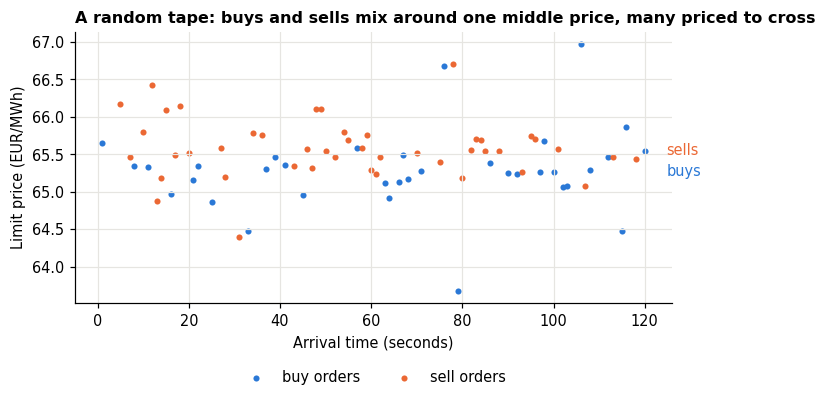

In [6]:
# One question, one figure: what does a random tape look like?
rows = tape[tape[:, 4] > 0]
t, px = rows[:, 6], np.array([decode_price(int(p), PC) for p in rows[:, 2]])
buy = rows[:, 1] == Side.BUY
fig, ax = plt.subplots()
ax.scatter(t[buy], px[buy], s=16, color=BUY, lw=0, label="buy orders")
ax.scatter(t[~buy], px[~buy], s=16, color=SELL, lw=0, label="sell orders")
x_end = t.max() * 1.04
ax.text(x_end, np.median(px[buy]), "buys", color=BUY, va="center")
ax.text(x_end, np.median(px[~buy]), "sells", color=SELL, va="center")
ax.set_xlabel("Arrival time (seconds)")
ax.set_ylabel("Limit price (EUR/MWh)")
ax.set_title("A random tape: buys and sells mix around one middle price, many priced to cross")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.2))
plt.show()

## 5. Stacking tapes of different lengths

A replay compiles the engine for one tape shape. `stack_tapes` pads every tape to the length of the
longest one, plus a few padding rows, and returns one array of shape (number of tapes, rows, 13). The
hand-built tape and three random tapes become one block. That block is also what a `Session` takes.

In [7]:
NAMES = ["by hand", "seed 0", "seed 1", "seed 2"]
randoms = [make_random_session(seed, regime).tape for seed in (SEED, SEED + 1, SEED + 2)]
tapes = stack_tapes([hand, *randoms])
print(f"Stacked shape: {tapes.shape}")
for name, one in zip(NAMES, tapes):
    n_real = int((one[:, 4] > 0).sum())
    print(f"  {name:8s} {n_real:4d} orders, {len(one) - n_real:4d} padding rows")

Stacked shape: (4, 96, 13)
  by hand     8 orders,   88 padding rows
  seed 0     80 orders,   16 padding rows
  seed 1     80 orders,   16 padding rows
  seed 2     80 orders,   16 padding rows


Every tape now has the same shape, so the engine compiles once and replays the other tapes fast.
For each tape, the summary gives the number of trades, the traded quantity and the volume-weighted
average price, in which each trade counts in proportion to its quantity:

$$\bar p = \frac{\sum_i p_i \, q_i}{\sum_i q_i}.$$

In [8]:
for name, one in zip(NAMES, tapes):
    t0 = time.perf_counter()
    trades = np.asarray(replay_orders_through_book(jnp.asarray(one), book, NO_TRADES).replayed_trades)
    seconds = time.perf_counter() - t0
    price, qty = trades[:, 0].astype(float), trades[:, 1].astype(float)
    vwap = f"{(price * qty).sum() / qty.sum():.2f} EUR/MWh" if len(trades) else "no trade"
    print(f"  {name:8s} {len(trades):3d} trades, {qty.sum():6.1f} MW, average price {vwap}  ({seconds:.1f} s)")

  by hand    3 trades,    5.0 MW, average price 51.00 EUR/MWh  (10.4 s)
  seed 0    26 trades,   80.3 MW, average price 65.35 EUR/MWh  (0.2 s)


  seed 1    27 trades,   92.7 MW, average price 60.42 EUR/MWh  (0.2 s)
  seed 2    36 trades,  122.0 MW, average price 50.40 EUR/MWh  (0.2 s)


## 6. The same tapes in a session

A `Session` replays a tape on the market clock and lets you add your own orders between the tape's
orders. Here it only replays the background flow of the tape `tape_idx=1` (seed 0), eight orders per
step, with no order of your own. [T05](T05_session.ipynb) explains the session, its clock and its
pitfalls.

In [9]:
session = Session({"tapes": tapes, "orders_per_step": 8})
state = session.reset(key).replace(tape_idx=jnp.int32(1))  # choose the tape (seed 0) instead of a random one
max_steps = session.steps_per_episode                     # enough steps to replay every row of the tape
for step in range(1, max_steps + 1):
    state, report, done = session.step(key, state, None)   # None: no order of your own
    if done:
        break
tob = session.top_of_book(state)
print(f"Replayed {int(state.tape_cursor)} tape rows in {step} steps; the clock reached minute {int(state.time)} of 60"
      " (the session's default window for synthetic tapes)")
print(f"Gate closure reached: {'yes' if bool(done) else 'no'}")
print(f"Best bid {float(tob.p_bid):.2f} EUR/MWh, best ask {float(tob.p_ask):.2f} EUR/MWh at the end")

Replayed 96 tape rows in 12 steps; the clock reached minute 34 of 60 (the session's default window for synthetic tapes)
Gate closure reached: no
Best bid 65.55 EUR/MWh, best ask 65.57 EUR/MWh at the end


The loop is bounded by the length of the tape, not only by `done`. The 60 minutes are the session's
default window for synthetic tapes; a real contract $k$ trades for $460 + 60\lfloor k/4 \rfloor$ minutes
([Market model › Trading window](../docs/market-model.md#trading-window-and-gate-closure)). With the default clock for synthetic
tapes, the session stretches the latest arrival time of the whole block over the trading window. A tape
whose last order comes earlier than that, like this one, is used up before the clock reaches gate
closure, and `done` never turns true. [T05](T05_session.ipynb) explains the clock and how to set it.

## Recap

- A tape is a time-ordered array of order rows with 13 integer columns; padding rows (order id and time
  $\le 0$) are skipped by the engine.
- `TapeBuilder.add` writes orders in EUR/MWh and MW; `build` returns the padded tape.
- `make_random_session(seed, FuzzRegime(...))` draws reproducible random flow: same seed, same tape.
- `stack_tapes` gives tapes of different lengths one shape, so the engine compiles once; the block
  feeds a `ContractBook` replay or a `Session`.

## Exercises

1. **An iceberg whose price moves.** In the hand-built tape, give the iceberg a price increment of
   0.50 EUR/MWh (an iceberg with price increment, ICEwPI), and replay. At which prices does the buy trade
   now? *Hint:* `ppd_eur=0.5` in `tb.add`; each new peak of the iceberg is 0.50 EUR/MWh dearer.
2. **More crossing.** Draw seed 0 with `cross_prob=0.6` and replay it. Does it make more trades than with
   0.3? *Hint:* `dataclasses.replace(regime, cross_prob=0.6)`.
3. **Shapes.** Draw seeds 10 to 14 with `n_orders=16, 48, 80, 48, 16` and stack them. What is the stacked
   shape, and why? *Hint:* the longest tape sets the length.

The solutions are in the collapsed cell at the end.

## Further reading

- [Data › Synthetic tapes](../docs/data.md#synthetic-tapes) and [the tape layout](../docs/data.md#the-tape-layout).
- [The market model](../docs/market-model.md): order types, price-time priority and ticks.
- Other tutorials: [T03](T03_real_data.ipynb) loads a real tape from OMIE's files;
  [T05](T05_session.ipynb) trades your own orders in a session on these tapes.

## Solutions

In [10]:
# Solutions to the exercises (collapsed; expand to read).
# 1. The same tape, with an iceberg whose new peaks move 0.50 EUR/MWh away from the buyers.
tb1 = TapeBuilder(timestamp_step=30)
for i in range(3):
    tb1.add(side=Side.BUY, price_eur=49.0 - i, qty_mw=2.0)
    tb1.add(side=Side.SELL, price_eur=51.0 + i, qty_mw=2.0)
tb1.add(side=Side.SELL, price_eur=51.0, qty_mw=6.0, peak_qty_mw=2.0, ppd_eur=0.5, exec_restriction=ExecRestriction.ICE)
tb1.add(side=Side.BUY, price_eur=52.0, qty_mw=5.0, exec_restriction=ExecRestriction.IOC)
res1 = replay_orders_through_book(jnp.asarray(tb1.build()), book, NO_TRADES)
print("1.", ", ".join(f"{q:.1f} MW at {p:.2f}" for p, q, _ in np.asarray(res1.replayed_trades)))

# 2. More crossing orders: the same seed, cross_prob 0.6 instead of 0.3.
crossing = make_random_session(SEED, dataclasses.replace(regime, cross_prob=0.6)).tape
n2 = len(replay_orders_through_book(jnp.asarray(crossing), book, NO_TRADES).replayed_trades)
n1 = len(replay_orders_through_book(jnp.asarray(randoms[0]), book, NO_TRADES).replayed_trades)
print(f"2. {n2} trades with cross_prob 0.6, against {n1} with 0.3")

# 3. The longest tape (80 orders and 8 padding rows) plus 8 more padding rows sets the length.
mixed = [make_random_session(s, dataclasses.replace(regime, n_orders=n)).tape
         for s, n in zip(range(10, 15), (16, 48, 80, 48, 16))]
print(f"3. {stack_tapes(mixed).shape}")

1. 2.0 MW at 51.00, 2.0 MW at 51.00, 1.0 MW at 51.50


2. 48 trades with cross_prob 0.6, against 26 with 0.3
3. (5, 96, 13)
